# Zomato delivery-time data audit

This notebook checks every CSV record for data-quality issues. It reads the project's raw CSV and, when available, the existing cleaned Parquet. It does not write either file.

Use the backend Python environment as the kernel. Install the backend requirements and add `matplotlib` and `ipykernel` to that environment. Run all cells in order.

The target plots describe data quality across the full file. Model exploration, feature selection, and fitting learned transformations belong on the training split.

In [1]:
import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


cwd = Path.cwd().resolve()
backend = next(
    (
        candidate
        for parent in (cwd, *cwd.parents)
        for candidate in (parent, parent / "apps" / "backend")
        if (candidate / "ml" / "configs" / "dataset.yaml").is_file()
        and (candidate / "app" / "main.py").is_file()
    ),
    None,
)
if backend is None:
    raise FileNotFoundError("Open this notebook from within the project repository.")
if str(backend) not in sys.path:
    sys.path.insert(0, str(backend))

from ml.manifest import load_dataset_config, resolve_dataset_paths
from ml.preprocessing import (
    CATEGORICAL_COLUMNS,
    COORDINATE_COLUMNS,
    clean_coordinates,
    normalize_text,
    parse_delivery_time,
    parse_numeric,
    parse_order_timestamp,
)
from ml.validation import numeric_violations, read_raw_csv


def sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


config = load_dataset_config()
paths = resolve_dataset_paths()
schema = config["schema"]
quality = config["quality"]
source = paths.raw_csv

if not source.is_file():
    alternate = source.with_name("Zomato Dataset.csv")
    if not alternate.is_file():
        raise FileNotFoundError(f"Expected {source.name} or {alternate.name} in ml/data/raw/.")
    source = alternate
    print(f"Default CSV is absent. Auditing {source.name} in place.")

raw_hash = sha256(source)
raw = read_raw_csv(source, schema["required_columns"])
normalized = raw.apply(normalize_text, missing_markers=quality["missing_markers"])
print(f"Raw file: {source.name} | {len(raw):,} records | {raw.shape[1]} columns")

Default CSV is absent. Auditing Zomato Dataset.csv in place.


Raw file: Zomato Dataset.csv | 45,584 records | 20 columns


## Missing values and category labels

Count blanks and configured missing markers after trimming whitespace. Frequencies use all nonmissing records. The table flags spelling variants and labels below 1% for review. Frequency alone does not justify removing a label.

In [2]:
missing = normalized.isna().sum()
missing_table = pd.DataFrame({
    "Missing rows": missing,
    "Missing %": missing.div(len(raw)).mul(100).round(2),
    "Distinct nonmissing": normalized.nunique(),
}).sort_values("Missing rows", ascending=False)
display(missing_table)

category_rows = []
for column in CATEGORICAL_COLUMNS:
    values = normalized[column].dropna()
    variants = values.groupby(values.str.casefold()).nunique()
    for label, count in values.value_counts().items():
        share = 100 * count / len(values)
        notes = []
        if column == "City" and label.casefold() == "metropolitian":
            notes.append("Standardize to Metropolitan")
        if variants.loc[label.casefold()] > 1:
            notes.append("Mixed casing")
        if share < 1:
            notes.append("Rare label")
        category_rows.append((column, label, count, round(share, 2), ", ".join(notes)))

categories = pd.DataFrame(
    category_rows, columns=["Column", "Observed label", "Rows", "Share %", "Review"]
)
display(categories)

,Missing rows,Missing %,Distinct nonmissing
Delivery_person_Ratings,1908,4.19,28
Delivery_person_Age,1854,4.07,22
Time_Orderd,1731,3.80,176
City,1200,2.63,3
multiple_deliveries,993,2.18,4
Weather_conditions,616,1.35,6
Road_traffic_density,601,1.32,4
Festival,228,0.50,2
ID,0,0.00,45584
Delivery_person_ID,0,0.00,1320


,Column,Observed label,Rows,Share %,Review
0,Weather_conditions,Fog,7653,17.02,
1,Weather_conditions,Stormy,7584,16.87,
2,Weather_conditions,Cloudy,7533,16.75,
3,Weather_conditions,Sandstorms,7494,16.67,
4,Weather_conditions,Windy,7422,16.51,
5,Weather_conditions,Sunny,7282,16.19,
6,Road_traffic_density,Low,15476,34.40,
7,Road_traffic_density,Jam,14139,31.43,
8,Road_traffic_density,Medium,10945,24.33,
9,Road_traffic_density,High,4423,9.83,


## Exact duplicates and conflicting order IDs

Exact duplicates match on every original CSV field. After exact deduplication, distinct records with the same trimmed, nonmissing order ID count as conflicts. The production policy flags conflicts and keeps records with valid targets for review.

In [3]:
exact_duplicates = raw.duplicated(keep="first")
all_ids = normalized["ID"]
repeated_ids = all_ids[all_ids.notna() & all_ids.duplicated(keep=False)]
deduplicated_ids = normalized.loc[~exact_duplicates, "ID"]
conflicting_ids = deduplicated_ids[
    deduplicated_ids.notna() & deduplicated_ids.duplicated(keep=False)
]

duplicate_summary = pd.Series({
    "Exact duplicate rows beyond the first": int(exact_duplicates.sum()),
    "Repeated raw order IDs": repeated_ids.nunique(),
    "Raw rows in repeated-ID groups": len(repeated_ids),
    "Conflicting order IDs after exact deduplication": conflicting_ids.nunique(),
    "Rows in conflicting-ID groups": len(conflicting_ids),
}, name="Count")
display(duplicate_summary.to_frame())

,Count
Exact duplicate rows beyond the first,0
Repeated raw order IDs,0
Raw rows in repeated-ID groups,0
Conflicting order IDs after exact deduplication,0
Rows in conflicting-ID groups,0


## Order timestamps

The source uses day-month-year dates and either a clock time or a fractional day for the order time. A fraction of 1 means midnight on the following date. Missing date or time values leave the timestamp null. Pickup time plays no part in this calculation.

In [4]:
timestamps, timestamp_audit = parse_order_timestamp(
    normalized["Order_Date"], normalized["Time_Orderd"]
)
timestamp_counts = pd.Series({
    name: count for name, count in timestamp_audit.items() if name != "rule"
}, name="Rows")
display(timestamp_counts.to_frame())
if timestamps.notna().any():
    print(f"Observed timestamp range: {timestamps.min()} to {timestamps.max()}")

,Rows
missing_date,0
invalid_date,0
missing_time,1731
invalid_time,0
fractional_day_times,4068
midnight_rollovers,430
out_of_range_timestamp,0
null_timestamp,1731


Observed timestamp range: 2022-02-11 08:10:00 to 2022-04-07 00:00:00


## GPS coordinates and numeric ranges

Check finite, in-range latitude and longitude for each endpoint. Treat `(0, 0)` as an unknown endpoint for this dataset. A single zero coordinate or a zero distance can be valid. Distances use the Haversine straight-line calculation. The configured distance cutoff flags suspect routes while preserving their source coordinate signs for review.

In [5]:
_, distances, gps = clean_coordinates(normalized, quality["max_straight_line_distance_km"])
display(pd.DataFrame(gps["coordinate_pair_issues"]).rename_axis("Issue"))

print(f"Distance cutoff: {gps['max_plausible_km']:g} km")
display(pd.DataFrame({
    "Rows": [gps["rows_with_invalid_coordinate_pair"], gps["implausible_distances"],
             distances.isna().sum(), gps["implausible_distances_with_negative_restaurant_coordinates"]],
}, index=[
    "At least one invalid endpoint",
    "Distance above cutoff",
    "Null distance after both checks",
    "Above cutoff with a negative restaurant coordinate",
]))
display(pd.DataFrame({
    "Before cutoff": gps["pre_cutoff_km"],
    "Above cutoff": gps["excluded_km"],
    "Retained": gps["retained_km"],
}).round(2).rename_axis("Distance (km)"))

numeric_audit = {}
for column in (*COORDINATE_COLUMNS, *quality["numeric_fields"]):
    values, issues = parse_numeric(normalized[column])
    rule = quality["numeric_fields"].get(column)
    if rule is not None:
        issues.update(numeric_violations(values, rule))
    numeric_audit[column] = {
        "Minimum": values.min(),
        "Maximum": values.max(),
        **{reason: int(mask.sum()) for reason, mask in issues.items()},
    }

display(pd.DataFrame.from_dict(numeric_audit, orient="index").round(4))
ages, _ = parse_numeric(normalized["Delivery_person_Age"])
under_18 = int(ages.lt(18).sum())
print(f"Rider ages below 18 to verify: {under_18:,}")

,restaurant,delivery
Issue,,
missing_component,0,0
malformed_component,0,0
non_finite_component,0,0
out_of_range,0,0
zero_pair,3640,0
invalid_pair,3640,0


Distance cutoff: 100 km


,Rows
At least one invalid endpoint,3640
Distance above cutoff,431
Null distance after both checks,4071
Above cutoff with a negative restaurant coordinate,431


,Before cutoff,Above cutoff,Retained
Distance (km),,,
min,1.47,2216.07,1.47
median,9.22,5897.02,9.19
max,19692.70,19692.70,20.97


,Minimum,Maximum,missing,malformed,non_finite,out_of_range,not_integer
Restaurant_latitude,-30.9056,30.9141,0,0,0,NaN,NaN
Restaurant_longitude,-88.3662,88.4335,0,0,0,NaN,NaN
Delivery_location_latitude,0.0100,31.0541,0,0,0,NaN,NaN
Delivery_location_longitude,0.0100,88.5635,0,0,0,NaN,NaN
Delivery_person_Age,15.0000,50.0000,1854,0,0,0.0,0.0
Delivery_person_Ratings,1.0000,6.0000,1908,0,0,53.0,0.0
Vehicle_condition,0.0000,3.0000,0,0,0,0.0,0.0
multiple_deliveries,0.0000,3.0000,993,0,0,0.0,0.0


Rider ages below 18 to verify: 38


## Delivery times and comparison with the cleaned dataset

The histogram shows finite, positive values parsed from `Time_taken (min)`. The rejection table covers all other raw values. When the Parquet is present, compare the two distributions using the same bins and scales. Shared-column missingness compares source blanks and missing markers with cleaned nulls. Validation can add nulls to fields that were populated in the CSV.

,Raw rows
missing,0
malformed,0
non_finite,0
non_positive,0


Valid raw delivery times above 60 minutes: 0


,Rows
Raw CSV,45584
Cleaned Parquet,45584


Raw and cleaned target frequencies match exactly.


,Raw missing,Cleaned null,Change
ID,0,0,0
Delivery_person_ID,0,0,0
Delivery_person_Age,1854,1854,0
Delivery_person_Ratings,1908,1961,53
Restaurant_latitude,0,3640,3640
Restaurant_longitude,0,3640,3640
Delivery_location_latitude,0,0,0
Delivery_location_longitude,0,0,0
Weather_conditions,616,616,0
Road_traffic_density,601,601,0


,Derived nulls
order_timestamp,1731
distance_km,4071


,count,min,25%,median,75%,max
Raw CSV,45584.0,10.0,19.0,26.0,32.0,54.0
Cleaned Parquet,45584.0,10.0,19.0,26.0,32.0,54.0


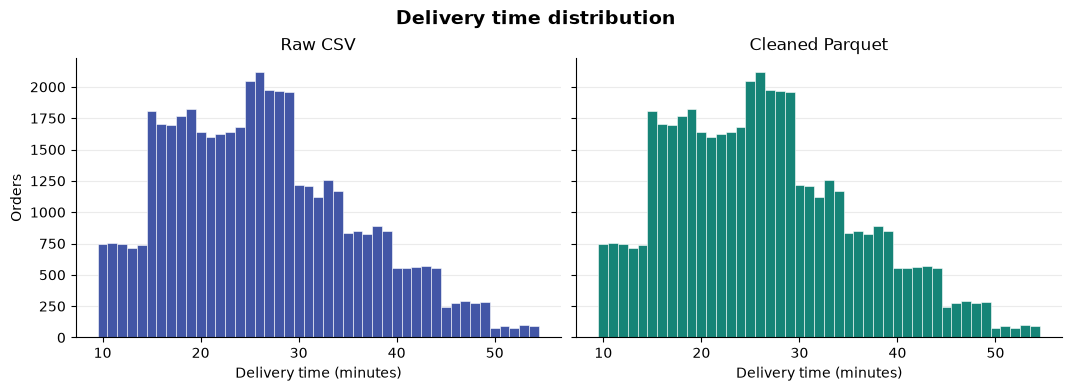

In [6]:
raw_minutes, target_issues = parse_delivery_time(normalized[schema["raw_target_column"]])
review_minutes = quality["long_delivery_review_minutes"]
long_deliveries = int(raw_minutes.gt(review_minutes).sum())
display(pd.Series(target_issues, name="Raw rows").to_frame())
print(f"Valid raw delivery times above {review_minutes:g} minutes: {long_deliveries:,}")

parquet = paths.processed_parquet
cleaned = pd.read_parquet(parquet) if parquet.is_file() else None
targets = {"Raw CSV": raw_minutes}
if cleaned is not None:
    clean_target = schema["target_column"]
    targets["Cleaned Parquet"] = cleaned[clean_target]
    display(pd.Series({"Raw CSV": len(raw), "Cleaned Parquet": len(cleaned)}, name="Rows").to_frame())
    frequencies = pd.concat(
        [values.value_counts() for values in targets.values()], axis=1
    ).fillna(0)
    match = frequencies.iloc[:, 0].eq(frequencies.iloc[:, 1]).all()
    print(f"Raw and cleaned target frequencies {'match exactly' if match else 'differ'}.")
    shared_columns = [column for column in normalized.columns if column in cleaned.columns]
    comparison = {
        column: (int(missing[column]), int(cleaned[column].isna().sum()))
        for column in shared_columns
    }
    comparison[clean_target] = (
        int(missing[schema["raw_target_column"]]), int(cleaned[clean_target].isna().sum())
    )
    missing_comparison = pd.DataFrame.from_dict(
        comparison, orient="index", columns=["Raw missing", "Cleaned null"]
    )
    missing_comparison["Change"] = missing_comparison["Cleaned null"] - missing_comparison["Raw missing"]
    display(missing_comparison)
    display(cleaned[["order_timestamp", "distance_km"]].isna().sum().to_frame("Derived nulls"))
else:
    print("Cleaned Parquet is absent. Showing the raw distribution only.")

distribution_stats = pd.DataFrame(targets).describe().T[["count", "min", "25%", "50%", "75%", "max"]]
display(distribution_stats.rename(columns={"50%": "median"}).round(2))

histogram_values = [values.dropna().to_numpy(dtype=float) for values in targets.values()]
combined = np.concatenate(histogram_values)
if combined.size:
    bins = 40
    low, high = np.floor(combined.min()), np.ceil(combined.max())
    if high - low <= 120:
        bins = np.arange(low - 0.5, high + 1.5)
    common_bins = np.histogram_bin_edges(combined, bins=bins)
    fig, axes = plt.subplots(
        1, len(targets), figsize=(5.3 * len(targets), 3.8), sharex=True, sharey=True,
        layout="constrained",
    )
    for axis, label, values, color in zip(
        np.atleast_1d(axes), targets, histogram_values, ["#4256A6", "#168477"]
    ):
        axis.hist(values, bins=common_bins, color=color, edgecolor="white", linewidth=0.4)
        axis.set(title=label, xlabel="Delivery time (minutes)")
        axis.set_axisbelow(True)
        axis.grid(axis="y", alpha=0.25)
        axis.spines[["top", "right"]].set_visible(False)
    np.atleast_1d(axes)[0].set_ylabel("Orders")
    fig.suptitle("Delivery time distribution", fontsize=14, fontweight="bold")
    plt.show()
else:
    print("No finite, positive delivery times to plot.")

## Cleaning methods and results

Results from the saved run on all 45,584 source rows.

| What was cleaned | Method used | Actual result |
| --- | --- | --- |
| Delivery time | Renamed `Time_taken (min)` to `delivery_time_minutes`, parsed it as a number, and checked that each value was finite and positive. | All targets passed. They ranged from 10 to 54 minutes, with a median of 26 minutes. |
| Category labels | Trimmed whitespace, standardized casing, and converted blanks and `NaN` markers to null. | Corrected 34,087 `Metropolitian` labels to `Metropolitan`. Meaningful labels such as `bicycle` and `Semi-Urban` were kept. |
| Rider and vehicle values | Converted age, ratings, vehicle condition, and multiple deliveries to numeric types. Applied range checks and preserved valid zeros. | Set 53 ratings above 5 to null. Kept 38 ages below 18 and counted them for review. |
| Order date and time | Combined the date and order time into a timestamp, then derived the hour and day of week. Parsed fractional times such as `0.833333333` as `20:00`. | Parsed 4,068 fractional times, including 430 midnight rollovers. 1,731 timestamps stayed null because the order time was missing. |
| GPS coordinates | Validated both coordinate pairs and calculated straight-line distance with the Haversine formula. Set distance to null for missing or invalid endpoints and distances over 100 km. | 4,071 distances became null, including 3,640 zero restaurant coordinate pairs and 431 implausibly long routes. |
| Duplicate orders | Compared complete CSV records for exact duplicates and checked trimmed order IDs for conflicts. | Found zero exact duplicates and zero conflicting order IDs. |

## Preprocessing decisions

These checks document the rules in [`preprocessing.py`](../preprocessing.py). They leave imputation, encoding, scaling, and model evaluation for the training workflow. The timestamp is available for a future chronological split. Rider, vehicle, batching, weather, and traffic snapshot availability needs confirmation before those fields are used as model inputs.

In [7]:
typos = int(normalized["City"].str.casefold().eq("metropolitian").sum())
ratings_outside = numeric_audit["Delivery_person_Ratings"]["out_of_range"]
decisions = [
    ("Fix", "Trim labels, normalize casing and map Metropolitian to Metropolitan.",
     f"{typos:,} misspelled city labels"),
    ("Fix", "Remove exact repeats and reject unusable targets. Keep missing features null.",
     f"{exact_duplicates.sum():,} duplicate rows; {sum(target_issues.values()):,} target rejections"),
    ("Fix", "Parse verified order-time formats and set out-of-range ratings to null.",
     f"{timestamps.isna().sum():,} null timestamps; {ratings_outside:,} ratings outside the scale"),
    ("Keep", "Retain meaningful rare labels, valid numeric zeros, and valid long deliveries.",
     f"{long_deliveries:,} valid targets above the review threshold"),
    ("Investigate", "Suppress suspect distances. Verify endpoint values or signs before correction.",
     f"{gps['rows_with_invalid_coordinate_pair']:,} invalid endpoints by row; "
     f"{gps['implausible_distances']:,} distances above cutoff"),
    ("Investigate", "Review conflicting IDs and unusually low rider ages against the source.",
     f"{conflicting_ids.nunique():,} conflicting IDs; {under_18:,} ages below 18"),
]
display(pd.DataFrame(decisions, columns=["Action", "Rule", "Result"]))
assert sha256(source) == raw_hash, "Raw CSV changed during the audit."
print("Raw CSV SHA-256 is unchanged.")

,Action,Rule,Result
0,Fix,"Trim labels, normalize casing and map Metropol...","34,087 misspelled city labels"
1,Fix,Remove exact repeats and reject unusable targe...,0 duplicate rows; 0 target rejections
2,Fix,Parse verified order-time formats and set out-...,"1,731 null timestamps; 53 ratings outside the ..."
3,Keep,"Retain meaningful rare labels, valid numeric z...",0 valid targets above the review threshold
4,Investigate,Suppress suspect distances. Verify endpoint va...,"3,640 invalid endpoints by row; 431 distances ..."
5,Investigate,Review conflicting IDs and unusually low rider...,0 conflicting IDs; 38 ages below 18


Raw CSV SHA-256 is unchanged.
